## Conversion Candidates

In [1]:
import sys 
from pathlib import Path 
import geopandas as gpd
import matplotlib.pyplot as plt 
import seaborn as sns

## Load candidates output

In [24]:
PROJECT_ROOT = Path("..").resolve()
sys.path.append(str(PROJECT_ROOT / "src"))
from config import GEOJSON_DIR, PROCESSED_DIR , CRS_WEB

gas_gdf = gpd.read_parquet(PROCESSED_DIR / 'conversion_candidates.parquet')
deserts_gdf = gpd.read_file(GEOJSON_DIR / 'charging_deserts.geojson')
ev_gdf = gpd.read_parquet(PROCESSED_DIR / 'ev_stations.parquet')

In [26]:
print(f"Loaded {len(gas_gdf)} gas stations for conversion candidates\n")
print(f"Loaded {len(deserts_gdf)} desert tracts\n")
print(f"Loaded {len(ev_gdf)} EV stations\n")
print(gas_gdf.columns)

Loaded 9591 gas stations for conversion candidates

Loaded 9129 desert tracts

Loaded 20254 EV stations

Index(['station_id', 'name', 'address', 'city', 'zip', 'source',
       'source_snapshot_date', 'geometry', 'GEOID', 'desert_score',
       'severity_score', 'total_population', 'population_density',
       'nearest_dcfc_km', 'nearby_gas_1km', 'redundancy_penalty',
       'nearest_highway_km', 'pts_local_gap', 'pts_dcfc_dist',
       'pts_pop_corridor', 'pts_suitability', 'planned_infra_penalty',
       'raw_score', 'final_score', 'rank'],
      dtype='object')


In [ ]:
# Display top 20 candidates
gas_gdf['final_score'].head(20)

0     70.578646
1     68.718913
2     68.409388
3     68.188614
4     68.188614
5     67.365568
6     67.248646
7     67.248646
8     67.101263
9     66.809537
10    66.770410
11    66.770410
12    66.667760
13    66.154540
14    66.144942
15    65.536834
16    65.486358
17    65.071144
18    64.924767
19    64.713716
Name: final_score, dtype: float64

In [12]:
gas_gdf['final_score'].describe()

count    9591.000000
mean       41.831911
std         6.334429
min        22.245950
25%        37.954262
50%        41.092340
75%        45.006143
max        70.578646
Name: final_score, dtype: float64

## Score review

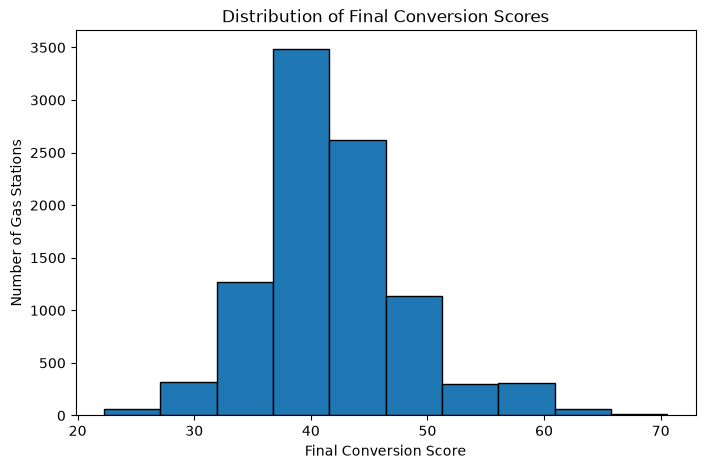

In [18]:
# Plot final score distribution
plt.figure(figsize=(8,5))
plt.hist(gas_gdf['final_score'], edgecolor='black', bins=10)
plt.xlabel('Final Conversion Score')
plt.ylabel('Number of Gas Stations')
plt.title('Distribution of Final Conversion Scores')
plt.show()

In [20]:
# Component columns for the top 50
# List the key metadata and score component columns
component_cols = [
    'rank',
    'name',                 # or station_id / address
    'city',
    'final_score',
    'pts_local_gap',        # max 30
    'pts_dcfc_dist',        # max 25
    'pts_pop_corridor',     # max 20
    'pts_suitability',      # max 15
    'redundancy_penalty',   # subtract up to 10
    'planned_infra_penalty',# subtract up to 10
    'nearest_dcfc_km',      # raw metric
    'nearest_highway_km',   # raw metric
    'nearby_gas_1km'        # raw metric
]

# Filter columns present in your dataframe and show top 50
available_cols = [col for col in component_cols if col in gas_gdf.columns]
top_50 = gas_gdf.sort_values(by='rank').head(50)[available_cols]

# Display in notebook
top_50.head(10)



,rank,name,city,final_score,pts_local_gap,pts_dcfc_dist,pts_pop_corridor,pts_suitability,redundancy_penalty,planned_infra_penalty,nearest_dcfc_km,nearest_highway_km,nearby_gas_1km
0,1,ARCO AM PM,PIXLEY,70.578646,18.130261,25.0,12.448385,15.0,0.00,0.0,21.672566,0.116913,0
1,2,Guys Corner,MADISON,68.718913,16.641560,25.0,12.077354,15.0,0.00,0.0,16.122083,1.322162,0
2,3,TEXACO,OCOTILLO,68.409388,17.753655,25.0,10.655732,15.0,0.00,0.0,19.957564,1.472233,0
3,4,HORNBROOK CHEVRON,HORNBROOK,68.188614,18.675233,25.0,9.513382,15.0,0.00,0.0,18.860284,0.287374,0
4,5,STATE LINE SERVICE,HORNBROOK,68.188614,18.675233,25.0,9.513382,15.0,0.00,0.0,28.536786,0.073941,0
5,6,PEPPERTREE,AGUA DULCE,67.365568,17.066903,25.0,10.298665,15.0,0.00,0.0,16.502782,3.578981,0
6,7,PRINCE FOOD MART,PIXLEY,67.248646,18.130261,25.0,12.448385,15.0,3.33,0.0,19.590959,0.091696,1
7,8,BEST TRUCK STOP,PIXLEY,67.248646,18.130261,25.0,12.448385,15.0,3.33,0.0,20.681342,0.048120,1
8,9,ROTTEN ROBBIE,LAKEPORT,67.101263,16.389012,25.0,10.712251,15.0,0.00,0.0,16.792907,2.220507,0
9,10,SIDEWINDER SHELL,WINTERHAVEN,66.809537,18.254320,25.0,8.555217,15.0,0.00,0.0,69.542493,0.096819,0


## Spatial Review

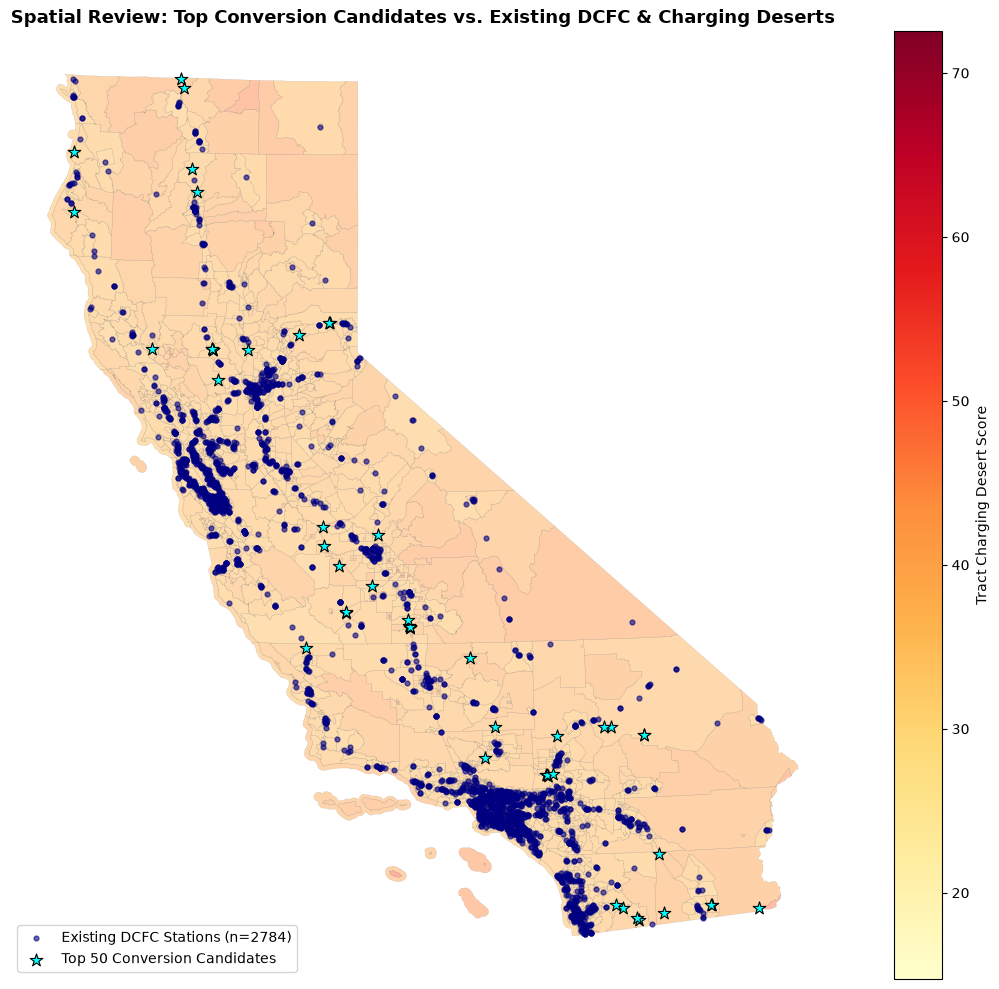

=== Spatial Review Sanity Check ===
Top 20 candidates mean distance to nearest DCFC: 20.66 km
Top 20 candidates min distance to nearest DCFC:  13.99 km
Top 20 candidates max distance to nearest DCFC:  69.54 km


In [27]:
# Map candidates over charging deserts tracts

dcfc_gdf = ev_gdf[ev_gdf['dcfc_ports'] > 0].copy()
top_50 = gas_gdf.sort_values(by='rank').head(50).copy()

if deserts_gdf.crs != gas_gdf.crs:
    deserts_gdf = deserts_gdf.to_crs(gas_gdf.crs)
if dcfc_gdf.crs != gas_gdf.crs:
    dcfc_gdf = dcfc_gdf.to_crs(gas_gdf.crs)

fig, ax = plt.subplots(figsize=(12, 10))
# Layer 1: Background — Charging Desert Tracts colored by score
deserts_gdf.plot(
    ax=ax,
    column='desert_score',
    cmap='YlOrRd',
    legend=True,
    legend_kwds={'label': 'Tract Charging Desert Score'},
    alpha=0.45,
    edgecolor='gray',
    linewidth=0.2
)
# Layer 2: Overlay — Existing DCFC Stations
dcfc_gdf.plot(
    ax=ax,
    color='navy',
    markersize=12,
    alpha=0.6,
    label=f'Existing DCFC Stations (n={len(dcfc_gdf)})'
)
# Layer 3: Overlay — Top 50 Conversion Candidates
top_50.plot(
    ax=ax,
    color='cyan',
    edgecolor='black',
    linewidth=0.8,
    marker='*',
    markersize=90,
    label='Top 50 Conversion Candidates'
)
plt.title("Spatial Review: Top Conversion Candidates vs. Existing DCFC & Charging Deserts", fontsize=13, fontweight='bold')
plt.legend(loc='lower left', frameon=True)
plt.axis('off')
plt.tight_layout()
plt.show()
# 5. Sanity Check Statistics
top_20 = gas_gdf.sort_values(by='rank').head(20)
print("=== Spatial Review Sanity Check ===")
print(f"Top 20 candidates mean distance to nearest DCFC: {top_20['nearest_dcfc_km'].mean():.2f} km")
print(f"Top 20 candidates min distance to nearest DCFC:  {top_20['nearest_dcfc_km'].min():.2f} km")
print(f"Top 20 candidates max distance to nearest DCFC:  {top_20['nearest_dcfc_km'].max():.2f} km")
